# Designing a gas-filled MPC with `thunder4d.design`

This notebook walks through a complete design and explains every option on the way. The example
is a real cell: **18 mJ, 500 fs at 1030 nm compressed to 25 fs in argon**.

How the design helper works:

1. **You describe** the laser, the target and the constraints (what your hardware can take).
2. **`starting_points()`** enumerates cell geometries (gas, RoC, round trips, k, passes), removes
   the ones that a hard limit already excludes analytically, and guesses a pressure for each.
3. **`MPCDesigner.refine()`** runs every starting point through the fast 1+1D solver (fast1d),
   ranks them, and fine-tunes the best ones (pressure, number of passes, RoC).
4. **You read** the results: a ranked table, and a report per design with the margin to every limit.
5. **You validate** the chosen design: convergence of fast1d, then the full 4D simulation.

Requirements: `uv add "thunder4d[examples]"` (matplotlib) and Jupyter
(`uv run --with jupyter jupyter lab`).

In [1]:
import os

import numpy as np

from thunder4d.design import (
    Candidate, DesignProblem, Fast1DQuick, LaserSpec, Max, MPCDesigner, Target, evaluate,
    starting_points,
)
from thunder4d.design.catalog import GASES, MIRRORS, Coating, get_gas, register_mirror
from thunder4d.design.designer import herriott_k
from thunder4d.design.specs import LASER_PRESETS

WORKERS = max(1, (os.cpu_count() or 2) - 1)   # parallel processes for the 1+1D runs
print("Workers :", WORKERS)

Workers : 11


## 1. The laser — `LaserSpec`

| field | meaning |
|---|---|
| `energy_J`, `duration_fs`, `wavelength_nm` | pulse energy, FWHM intensity duration, central wavelength |
| `tl_duration_fs` | transform limit if the input is chirped (the chirp is added as positive GDD) |
| `shape` | `"gaussian"` or `"sech2"` |
| `prechirp_gdd_fs2`, `prechirp_tod_fs3` | spectral phase added before injection |
| `rep_rate_Hz` | used for the average power on the mirrors |
| `polarization` | `"linear"` or `"circular"` (n2 x 2/3, less ionisation) |

Datasheet presets exist for common front ends (values are the manufacturers' upper bounds):

In [2]:
print(sorted(LASER_PRESETS))
print(LaserSpec.preset("pharos_ph2_sp_2mJ", rep_rate_Hz=1e3))      # any field can be overridden

laser = LaserSpec(energy_J=18e-3, duration_fs=500.0, wavelength_nm=1030.0, rep_rate_Hz=1e3)
print(f"peak power {laser.peak_power_W / 1e9:.1f} GW, average power {laser.average_power_W:.0f} W")

['carbide_cb3_120w', 'carbide_cb3_20w', 'carbide_cb3_40w', 'carbide_cb3_80w_0.8mJ', 'carbide_cb3_80w_2mJ', 'carbide_cb5_5w', 'carbide_cb5_6w', 'carbide_cb5_sp', 'dira_1000_1', 'dira_1000_5', 'dira_200_1', 'dira_200_100', 'dira_500_10', 'mpc1_18mJ_350fs', 'pharos_ph2_10w', 'pharos_ph2_5mJ', 'pharos_ph2_sp_0.4mJ', 'pharos_ph2_sp_1mJ', 'pharos_ph2_sp_2mJ', 'pharos_ph2_up_0.4mJ', 'pharos_ph2_up_1mJ']
LaserSpec(energy_J=0.002, duration_fs=190.0, wavelength_nm=1030.0, tl_duration_fs=None, shape='gaussian', prechirp_gdd_fs2=0.0, prechirp_tod_fs3=0.0, rep_rate_Hz=1000.0, polarization='linear', name='pharos_ph2_sp_2mJ')
peak power 33.8 GW, average power 18 W


## 2. The target — `Target`

`objective` decides what "best" means:

| objective | the score is low when... |
|---|---|
| `"target_duration"` | the compressed duration is close to `target_duration_fs` |
| `"target_compression"` | input / output duration is close to `target_compression` |
| `"shortest"` | the compressed pulse is short |
| `"max_peak_power"` | the compressed peak power is high (duration *and* throughput) |
| `"weighted"` | a weighted sum of duration, throughput, length and pressure (`weights`) |

Two quality floors are checked on the result: `min_throughput` (default 80 %) and
`min_main_peak_fraction` (energy in the main peak of the compressed pulse, default 0.7). Both are
*soft*: they penalise the score instead of rejecting the design.

In [3]:
target = Target(objective="target_duration", target_duration_fs=25.0)
problem = DesignProblem(laser=laser, target=target)

## 3. Limits — the `Limit` object

Every constraint is a `Limit` with:

* `value` — the limit itself. `None` means *take it from the catalogue* (the coating LIDT, the gas
  ionisation threshold).
* `bound` — `"max"` (value must stay below) or `"min"` (above). Use the helpers `Max(...)`, `Min(...)`, `Off()`.
* `mode` — `"hard"` rejects a design, `"soft"` adds a penalty `weight * margin**2` to the score,
  `"off"` ignores it.
* `safety` — the limit actually applied is `value * safety` for a max (`value / safety` for a min).

The **margin** shown in the reports is the distance to the applied limit, relative to it: 20 %
means 20 % of headroom, a negative margin means violated.

> **Trap:** setting only `.value` keeps the existing `safety`. The ionisation limit has
> `safety=0.5` by default, so `value = 3.5e13` applies 1.75e13. Replace the whole limit
> (`Max(3.5e13)`) to reset it. The reports always print the limit actually applied.

In [4]:
lim = Max(3.5e13, safety=0.5)
print("applied limit:", lim.allowed(), "| margin of 1e13:", lim.slack(1e13), "| penalty of 2e13:", lim.penalty(2e13))

applied limit: 17500000000000.0 | margin of 1e13: 0.42857142857142855 | penalty of 2e13: inf


## 4. Constraints — `problem.constraints`

| group | knobs |
|---|---|
| `space` | `max_separation_m`, `chamber_margin_m`, `max_chamber_length_m`, `fixed_chamber_length_m` |
| `mirrors` | `allowed_roc_m`, `allowed_diameters_inch`, `allowed_coatings`, `fluence` (LIDT), `bandwidth` (energy outside the coating band), `max_average_power_W` |
| `kerr` | `p_over_pcr`, `b_per_pass_rad` (on-axis, per pass), `b_total_rad` |
| `ionization` | `peak_intensity_W_cm2` (at the waist) |
| `spots` | `min_spot_separation_w`, `edge_clearance_w`, `pattern_radius_m` |
| `pressure` | `pressure_bar` (min, max), `resolution_bar` (your regulator) |
| `gas` | `allowed` |

**Spot pattern and mirror size.** Each mirror carries M spots on a circle. By default the circle is
as large as the mirror allows: radius = mirror radius − `edge_clearance_w` × w_mirror. Adjacent
spots are then 2 r sin(π/M) apart, which must exceed `min_spot_separation_w` × w_mirror. Set
`pattern_radius_m` to impose your own radius (the edge clearance is then checked instead).

Here the limits are **calibrated on a cell known to work** (see section 12): this is the most
reliable way to set them.

In [5]:
C = problem.constraints
C.space.max_separation_m.value = 5.0                 # m
C.mirrors.allowed_roc_m = (1.0, 2.0, 3.0)            # what you can buy / have
C.mirrors.allowed_diameters_inch = (3.0,)
C.mirrors.allowed_coatings = ["dielectric_1030nm"]
C.mirrors.fluence.value = 0.7                        # J/cm2 (None -> coating LIDT)
C.kerr.b_per_pass_rad.value = 3.0                    # rad, on-axis per pass
C.ionization.peak_intensity_W_cm2 = Max(3.5e13)      # W/cm2, safety back to 1
C.pressure.pressure_bar = (0.0, 2.0)
C.gas.allowed = ("Ar", "Kr")

## 5. Catalogues — gases and mirror coatings

**Gases** (`thunder4d.design.catalog.GASES`): dispersion and n2 come from `thunder4d.materials`
(the same data as the 4D solver). The design catalogue adds the ionisation potential and an
ionisation threshold. The default threshold is only 0.2 × the barrier-suppression intensity:
**put your own values** with `with_()`.

**Mirrors** (`MIRRORS`): a `Coating` has a reflectivity R(λ) and a GDD(λ) per bounce (scalars or
tables), a usable band and a LIDT.Register your own coatings, or load vendor curves with `Coating.from_files(...)` or `load_catalog("coatings.json")`. Custom entries are copied to the parallel workers automatically.

In [6]:
for name in ("He", "Ar", "Kr"):
    g = get_gas(name)
    print(f"{name}: Ip = {g.ip_eV:.2f} eV, n2(1 bar) = {g.n2_per_bar:.2e} m2/W, threshold = {g.ionization_threshold:.2e} W/cm2")

# your own thresholds (example values: replace them with yours)
GASES["Ar"] = GASES["Ar"].with_(ionization_threshold_W_cm2=4e13)

# a coating of your own (scalar values here; tables: Coating.from_files("name", "R.csv", "GDD.csv", ...))
register_mirror(Coating("my_hr_1030", kind="dielectric", band_nm=(960.0, 1100.0), reflectivity=0.9995,
                        gdd_fs2=0.0, lidt_J_cm2=0.7, source="example"), overwrite=True)
print(sorted(MIRRORS))

He: Ip = 24.59 eV, n2(1 bar) = 3.50e-25 m2/W, threshold = 2.92e+14 W/cm2
Ar: Ip = 15.76 eV, n2(1 bar) = 1.00e-23 m2/W, threshold = 4.94e+13 W/cm2
Kr: Ip = 14.00 eV, n2(1 bar) = 2.80e-23 m2/W, threshold = 3.07e+13 W/cm2
['dielectric_1030nm', 'dielectric_800nm', 'enhanced_silver', 'my_hr_1030']


## 6. Cell geometry convention

A Herriott cell is set by its RoC **R**, the number of round trips **M** of one re-entrant cycle
and the index **k** (coprime with M, k < M/2):

* concentric branch: d = R (1 + cos(π k / M)), so d > R
* planar branch: d = R (1 − cos(π k / M)), so d < R

One cycle is **2 M passes** and puts **M spots** on each mirror. The number of passes actually used
can be anything from `min_passes` to 2 M. An odd number means the beam leaves on the other mirror.
`Candidate` holds one configuration:

In [7]:
cell = Candidate("Ar", 0.17, roc_m=2.0, round_trips=15, k=2, branch="concentric")   # n_passes = 2 M by default
w0, wm, zr = cell.linear_mode(laser.lambda0)
print(f"d = {cell.separation_m:.3f} m, {cell.n_passes} passes, w0 = {w0 * 1e6:.0f} um, w_mirror = {wm * 1e3:.2f} mm")
print("valid k for M = 15:", herriott_k(15))

d = 3.827 m, 30 passes, w0 = 365 um, w_mirror = 1.76 mm
valid k for M = 15: [1, 2, 4, 7]


## 7. The quick solver — `Fast1DQuick`

`Fast1DQuick` wraps the 1+1D code (fast1d) for the design helper:

* `accuracy`: `"fast"` (design loop, ~30–100 ms per run), `"default"` or `"fine"` (reference runs).
* `matching`: `"linear"` injects at the linear eigenmode of the cell, `"nonlinear"` at the
  Kerr-matched waist.
* `options`: any other fast1d input, e.g. `{"self_steepening": False}`.

The mirrors' R(λ) and GDD(λ) come from the coating. The compressor is a lossless GDD compressor,
and the optimal GDD is reported.

You can evaluate any configuration by hand. `report()` lists every limit, sorted from the tightest
to the loosest:

In [8]:
quick = Fast1DQuick(accuracy="fast")
evaluate(problem, cell, quick(problem, cell).as_metrics())
print(cell.report(problem))

KeyError: "unknown coating 'dielectic_1030nm'; available: ['dielectric_1030nm', 'dielectric_800nm', 'enhanced_silver', 'my_hr_1030']"

How to read a report:

* **output** — compressed duration (pure GDD compression), throughput, peak power.
* **score** — lower is better: objective + penalties of the soft limits (`REJECTED` if a hard limit is
  violated). Only the ranking of scores matters, not their absolute value.
* **limits** — value, limit actually applied, margin (negative = violated), mode. The first line
  is what constrains the design.
* **spots** — spots per mirror, pattern radius, spacing in units of the mirror spot size.
* **align** — information, not a constraint: how much the waist and the mirror spot change for a
  separation error and for the RoC tolerance (`problem.tolerance`). Near-concentric cells are the
  sensitive ones.

## 8. Search space — `problem.search` and `starting_points()`

| knob | meaning |
|---|---|
| `gases`, `roc_m`, `diameters_inch`, `coatings` | restrict the lists of the constraints (None = all allowed) |
| `branches` | `("concentric", "planar")` |
| `round_trips` | range of M, e.g. `(3, 40)` |
| `k_range` | restrict k (None = every valid k) |
| `pass_offsets` | passes tried per geometry: 2 M + offset (default `(0, -1)`: full cycle, and out on the other mirror) |
| `min_passes` | never fewer passes |

`starting_points(problem, k="all" | "smallest")` builds the grid, drops what the separation,
fluence, ionisation and spot limits already exclude analytically (conservatively), and guesses a
pressure for each geometry: the lowest of P/Pcr = 0.3, 90 % of the B-per-pass limit, and the
B-integral the target needs.

In [ ]:
problem.search.round_trips = (8, 25)
problem.search.branches = ("concentric",)
starts = starting_points(problem)

372 starting points kept (rejected analytically: fluence: 396, separation: 196, ionization: 128, spot_separation: 48)


## 9. Refinement — `problem.refinement` and `MPCDesigner`

| knob | meaning |
|---|---|
| `n_candidates` | how many configurations come out |
| `diversity` | spread them over gases first, then over (gas, RoC, branch) |
| `tune` | continuous parameters optimised: `"pressure_bar"`, `"prechirp_gdd_fs2"` |
| `neighbour_n_passes` | also try N ± this many passes in the same geometry |
| `neighbour_roc_steps` | also try the neighbouring RoCs of the allowed list (same M, k) |
| `method`, `max_evaluations`, `xtol_rel` | optimiser settings |

`refine()` evaluates every starting point, then refines the candidates in ranking order until
`n_candidates` feasible designs are found (or `max_attempts`, default 3 × n, have been tried).
`workers` runs the 1+1D simulations in parallel processes.

In [ ]:
problem.refinement.n_candidates = 3
problem.refinement.neighbour_n_passes = 1
problem.refinement.max_evaluations = 25

result = MPCDesigner(problem, quick=quick, workers=WORKERS).refine(starts)
print(result.table())

evaluating 372 starting points (1 worker(s))...


[1/3, try 1] Kr 0.050 bar, R = 2.0 m, N = 34, k = 3, concentric, d = 3.700 m, score start 0.0236 -> refined 0.0236


[2/3, try 2] Ar 0.170 bar, R = 2.0 m, N = 29, k = 2, concentric, d = 3.827 m, score start 0.047 -> refined 0.00916


[3/3, try 3] Kr 0.040 bar, R = 3.0 m, N = 50, k = 7, concentric, d = 4.912 m, score start 0.03 -> refined 0.03
 #  gas  p[bar]  R[m]   M   k    N     branch   d[m]  tau[fs]     T    score
 0   Ar   0.170  2.00  15   2   29 concentric  3.827     25.6 0.972  0.00916
 1   Kr   0.050  2.00  17   3   34 concentric  3.700     28.2 0.968   0.0236
 2   Kr   0.040  3.00  25   7   50 concentric  4.912     29.0 0.952     0.03


## 10. Reading and exporting the results

`result.refined` holds the designs and `result.best` the best one. `save_json()` stores the problem
and all designs. `best.to_cell()` gives the thunder4d `MPC` for the full 4D simulation.

In [ ]:
best = result.best
print(best.report(problem))
result.save_json("design_tutorial.json")
mpc = best.to_cell(polarization_factor=laser.n2_polarization_factor, lambda0_m=laser.lambda0)
print("\n4D cell:", mpc.report())

Ar 0.170 bar | R = 2.0 m, M = 15 round trips, k = 2, concentric, d = 3.827 m, 29 passes | generic_dielectric, 3"
  output : 25.6 fs (from 500 fs, x19.6), throughput 97.2 %, peak power 427 GW
  score  : 0.00916  = objective 0.000539 + penalties 0.00862   (lower is better)
  limit                    value           limit   margin  mode
  main_peak                0.635  >=         0.7      -9%  soft  <-- violated
  fluence [J/cm2]         0.5571  <=         0.7      20%  hard
  throughput              0.9724  >=         0.8      22%  soft
  b_per_pass [rad]         2.342  <=           3      22%  hard
  separation [m]           3.827  <=           5      23%  hard
  ionization [W/cm2]   2.412e+13  <=     3.5e+13      31%  hard
  p_over_pcr              0.3405  <=         0.5      32%  hard
  pressure [bar]            0.17  <=           2      92%  hard
  bandwidth             7.68e-07  <=        0.01     100%  hard
  spot_separation [w]       7.934  >=           3     164%  hard
  spots  


4D cell: MPC: R = 2.000 m, d = 3.8271 m, 29 passes, Gouy/pass = 156.00 deg, Material(Ar, 0.17 bar, n2 = 1.7e-24 m^2/W)


## 11. Validation

The design loop uses fast1d's `"fast"` settings. Before trusting a design, check that fast1d is
converged for it. `validate()` re-runs it with halved steps, a larger grid and double precision,
and reports how much each output moved (2 % tolerance by default). Call it with
`accuracy="default"` to check a reference run as well. Then look at the pulse itself.

In [ ]:
print(quick.validate(problem, best).summary())

fast1d validation (PASSED, tolerance 2.0 %)
  reference: fast settings, 1944 points, 286 steps, single precision
  check     quantity                   reference     variant   change
  numerics  conservation drift           3.9e-06     < 1e-04           ok
  numerics  grid edges                     clear                       ok
  steps     compressed FWHM [fs]           25.57       25.54    0.09%  ok
  steps     compressed peak power [GW]       427.1       427.1    0.01%  ok
  steps     compressor GDD [fs^2]          -2135       -2132    0.12%  ok
  steps     B-integral [rad]               62.69       62.72    0.05%  ok
  steps     transmission                  0.9724      0.9724    0.00%  ok
  steps     P/Pcr max                     0.3405      0.3405    0.00%  ok
  steps     peak intensity [W/cm^2]    2.412e+13   2.412e+13    0.00%  ok
  steps     mirror fluence [mJ/cm^2]       557.1       557.6    0.08%  ok
  steps     spectrum (L1 distance)             0    0.004256    0.43%  ok
 

Ar 170 mbar, linear, R = 2 m, d = 3.8271 m, 29 passes
w0 = 365 um, w_mirror = 1.756 mm (linear)
E in / out       : 18.000 / 17.503 mJ (T = 97.2 %)
B-integral       : 62.7 rad (on-axis)
P/Pcr max        : 0.341 (Pcr = 99.3 GW)
I max            : 2.412e+13 W/cm^2
F mirror max     : 557.6 mJ/cm^2
FWHM in / out    : 500.0 / 560.7 fs
FWHM comp / FTL  : 25.54 / 25.19 fs (x19.6)
GDD compression  : -2132 fs^2
P peak comp / FTL: 427.1 / 538.9 GW (ratio 0.79, lossless compressor)
885 steps, 8192 points, double precision, 0.779 s, conservation drift 7.4e-10


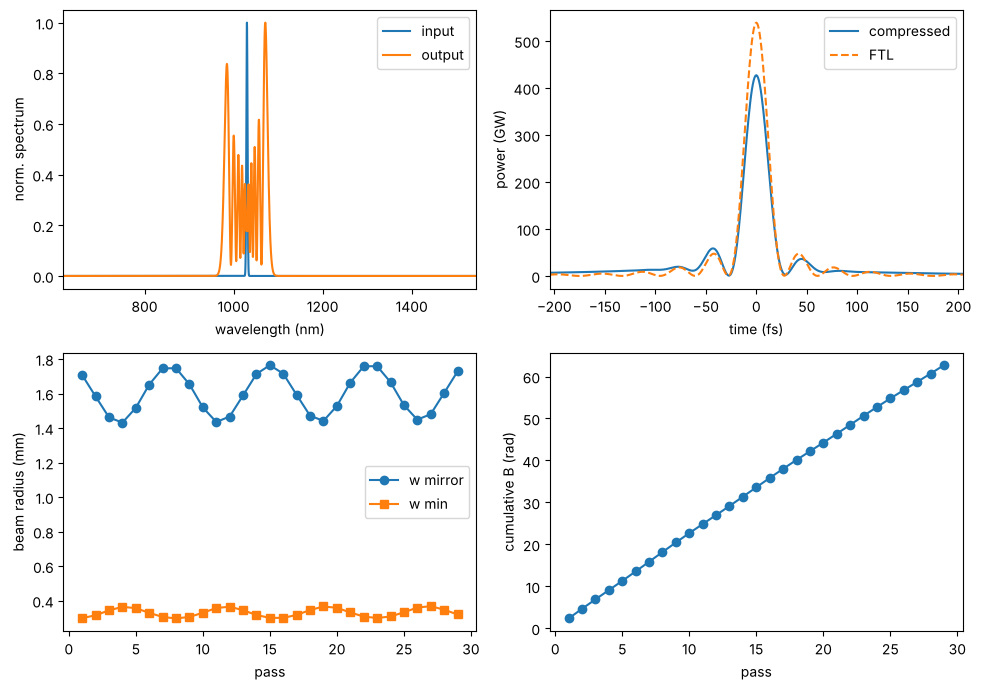

In [ ]:
out = quick.simulate(problem, best, accuracy="default")
print(out.summary())
out.plot();

## 12. Tips

* **Calibrate the limits on a cell you know works.** Evaluate your existing cell (as in section 7)
  and set B per pass, fluence and ionisation so that it passes. The helper then searches around
  what your hardware actually takes. With these limits, the helper finds this example cell
  (Ar ~170 mbar, R = 2 m, 15 round trips, k = 2) for 18 mJ / 500 fs → 25 fs.
* **Nothing feasible?** Read the "violated" lists printed by `refine()` and the first lines of the
  reports. A pressure at 0 % margin means the pressure ceiling is the limit.
* **Too many starting points?** Restrict `search.round_trips`, `search.roc_m` or `branches`, or use
  `starting_points(problem, k="smallest")`.
* **Few-cycle targets:** check `validate()`. The compressor removes GDD only, so the gap between
  the compressed duration and the FTL grows for very broad spectra.